In [15]:
import pandas as pd
from energy_demand.preprocessing import load_demand_data
from energy_demand.features import (
    add_calendar_features,
    add_lag_features,
    add_rolling_features
)

df = load_demand_data("../data/raw/time_series_60min_singleindex.csv")
df = add_calendar_features(df)
df = add_lag_features(df)
df = add_rolling_features(df)

print(df[["utc_timestamp", "day_of_week", "is_weekend", "hour", "rolling_mean_24", "rolling_mean_24_safe", "load_lag_24", "load_lag_168"]])
print(df.isnull().sum())

                  utc_timestamp  day_of_week  is_weekend  hour  \
0     2014-12-31 23:00:00+00:00            3           0     0   
1     2015-01-01 00:00:00+00:00            3           0     1   
2     2015-01-01 01:00:00+00:00            3           0     2   
3     2015-01-01 02:00:00+00:00            3           0     3   
4     2015-01-01 03:00:00+00:00            3           0     4   
...                         ...          ...         ...   ...   
50396 2020-09-30 19:00:00+00:00            2           0    21   
50397 2020-09-30 20:00:00+00:00            2           0    22   
50398 2020-09-30 21:00:00+00:00            2           0    23   
50399 2020-09-30 22:00:00+00:00            3           0     0   
50400 2020-09-30 23:00:00+00:00            3           0     1   

       rolling_mean_24  rolling_mean_24_safe  load_lag_24  load_lag_168  
0                  NaN                   NaN          NaN           NaN  
1                  NaN                   NaN          NaN  

In [14]:
feature_columns = [
    "hour",
    "day_of_week",
    "is_weekend",
    "load_lag_24",
    "load_lag_168",
    "rolling_mean_24_safe"
]

target_column = "load_mw"

clean_df = df.dropna(subset=feature_columns+[target_column])

X = clean_df[feature_columns]
y = clean_df[target_column]

print(f"X.shape = {X.shape}, missing values in X: {X.isnull().sum().sum()}")
print(f"y.shape = {y.shape}, missing values in y: {y.isnull().sum()}")

X.shape = (50232, 6), missing values in X: 0
y.shape = (50232,), missing values in y: 0


In [19]:
timestamps = clean_df["utc_timestamp"]

train_df = clean_df[timestamps < pd.Timestamp("2019-01-01", tz="UTC")]
val_df = clean_df[
    (timestamps >= pd.Timestamp("2019-01-01", tz="UTC")) &
    (timestamps < pd.Timestamp("2020-01-01", tz="UTC"))
]

test_df = clean_df[timestamps >= pd.Timestamp("2020-01-01", tz="UTC")]

print(train_df.shape)
print(val_df.shape)
print(test_df.shape)

assert len(train_df) + len(val_df) + len(test_df) == len(clean_df)

(34896, 9)
(8760, 9)
(6576, 9)


In [20]:
X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_val = val_df[feature_columns]
y_val = val_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]


In [25]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Weights:")
for column, value in zip(feature_columns, model.coef_):
    print(f"{column} = {value}")

print(f"Bias = {model.intercept_}")

Weights:
hour = 40.277681485274066
day_of_week = -807.1143236681503
is_weekend = -1299.591147948113
load_lag_24 = 0.39924205060239404
load_lag_168 = 0.5299340541175108
rolling_mean_24_safe = -0.06174119693261125
Bias = 9726.737003596645


In [31]:
import numpy as np

y_pred = model.predict(X_val)
print(y_pred[0:5])

errors = y_val.to_numpy() - y_pred
absolute_errors = np.abs(errors)
errors_squared = np.square(errors)

mae = np.mean(absolute_errors)
mse = np.mean(errors_squared)
rmse = np.sqrt(mse)

print(f"MAE: {mae:.2f} MW")
print(f"MSE: {mse:.2f} MW^2")
print(f"RMSE: {rmse:.2f} MW")


[43757.57949399 42762.50156991 42537.78662927 42888.21626518
 43394.98134714]
MAE: 2367.20 MW
MSE: 13019590.65 MW
RMSE: 3608.27 MW


In [35]:
daily_pred = X_val["load_lag_24"].to_numpy()
daily_errors = y_val.to_numpy() - daily_pred
daily_mae = np.mean(np.abs(daily_errors))
daily_mse = np.mean(np.square(daily_errors))
daily_rmse = np.sqrt(daily_mse)

print(f"Daily MAE: {daily_mae:.2f} MW")
print(f"Daily MSE: {daily_mse:.2f} MW^2")
print(f"Daily RMSE: {daily_rmse:.2f} MW")

weekly_pred = X_val["load_lag_168"].to_numpy()
weekly_errors = y_val.to_numpy() - weekly_pred
weekly_mae = np.mean(np.abs(weekly_errors))
weekly_mse = np.mean(np.square(weekly_errors))
weekly_rmse = np.sqrt(weekly_mse)

print(f"\nWeekly MAE: {weekly_mae:.2f} MW")
print(f"Weekly MSE: {weekly_mse:.2f} MW^2")
print(f"Weekly RMSE: {weekly_rmse:.2f} MW")

Daily MAE: 4557.69 MW
Daily MSE: 48219008.97 MW^2
Daily RMSE: 6943.99 MW

Weekly MAE: 2558.15 MW
Weekly MSE: 19935976.17 MW^2
Weekly RMSE: 4464.97 MW


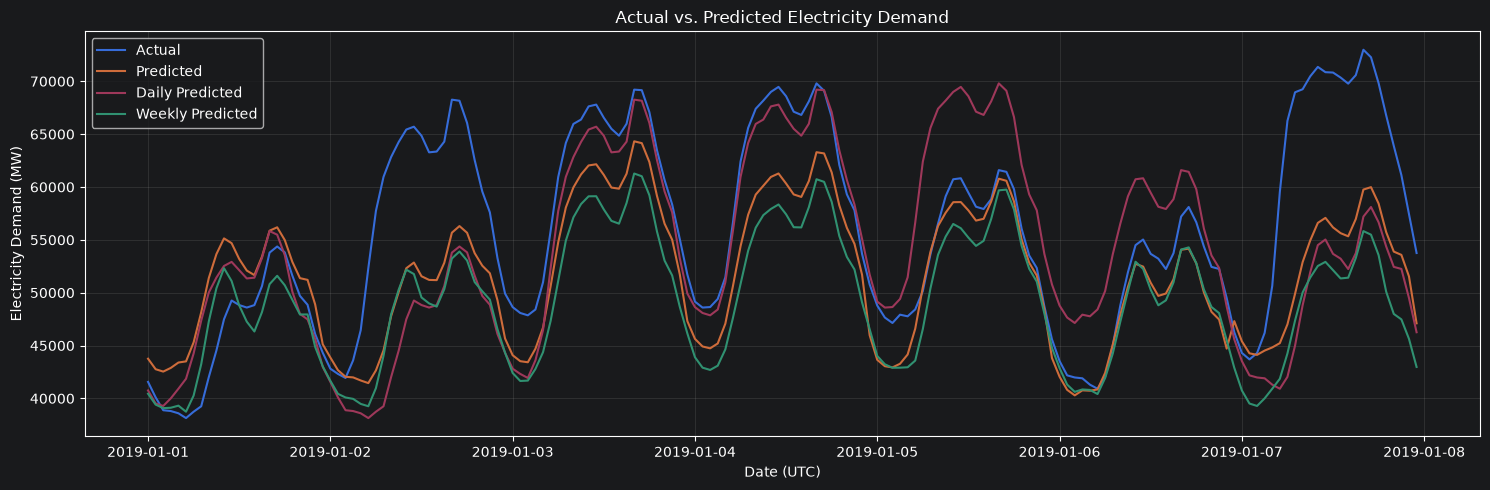

In [44]:
import matplotlib.pyplot as plt

hours = 168
timestamps = val_df["utc_timestamp"].iloc[:hours]

plt.figure(figsize=(15, 5))

plt.plot(
    timestamps,
    y_val.iloc[:hours],
    label="Actual"
)

plt.plot(
    timestamps,
    y_pred[:hours],
    label="Predicted"
)

plt.plot(
    timestamps,
    daily_pred[:hours],
    label="Daily Predicted"
)

plt.plot(
    timestamps,
    weekly_pred[:hours],
    label="Weekly Predicted"
)

plt.title("Actual vs. Predicted Electricity Demand")
plt.xlabel("Date (UTC)")
plt.ylabel("Electricity Demand (MW)")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.legend()